# TP — Reconnaissance de l'alphabet Tifinagh avec **LeNet-5**

**Pr. M. BENADDY — Pr. A. HADRI** · Masters IMSD & IAA · 2024-2025

**Dataset :** [AMHCD — Amazigh Handwritten Character Database](https://www.kaggle.com/datasets/benaddym/amazigh-handwritten-character-database-amhcd) (33 classes, images RGB 64×64)

**Objectifs du TP**

1. Implémenter LeNet-5 sous forme de **couches paramétrables** (convolution, pooling, fully connected) ;
2. Implémenter les fonctions d'apprentissage **train / validation / test** ;
3. Implémenter les algorithmes d'optimisation (**SGD, Adam, RMSprop**, …) ;
4. Visualiser les **courbes de loss / accuracy**, la **matrice de confusion** et les **cartes caractéristiques** (*feature maps*) ;
5. Produire des **résultats quantitatifs** (accuracy, precision, recall, F1) et **qualitatifs** (prédictions, erreurs).

> L'entrée du réseau est une image en **niveaux de gris 32 × 32** (1 canal), conformément à l'architecture du diagramme (l'image RGB du jeu de données est convertie en niveaux de gris).

## 1. Imports et configuration

In [17]:
import os, math, json, time, random, copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from PIL import Image

%matplotlib inline

# ---------- Reproductibilite ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------- Dispositif ----------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count() or 4)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True})
sns.set_style("whitegrid")

# ---------- Dossiers ----------
ROOT = Path.cwd()
if not (ROOT / "tp_CNN_Lenet5.pdf").exists():
    ROOT = Path(r"C:\Users\ASUS\Downloads\sana1")
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"
DATA_DIR = ROOT / "data"
for d in (FIG_DIR, MODEL_DIR, DATA_DIR):
    d.mkdir(exist_ok=True)

CACHE = DATA_DIR / "amhcd_cache.pt"

print(f"Device      : {DEVICE}")
print(f"Cores       : {os.cpu_count()}")
print(f"PyTorch     : {torch.__version__}")
print(f"Repertoire  : {ROOT}")

Device      : cpu
Cores       : 20
PyTorch     : 2.14.1+cpu
Repertoire  : C:\Users\ASUS\Downloads\sana1


## 2. Dataset AMHCD

Le jeu de données contient **33 classes** correspondant aux caractères les plus courants de l'alphabet **Tifinagh** (écriture amazighe), avec 780 images par classe (25 740 images au total).

In [18]:
import kagglehub

raw_path = Path(kagglehub.dataset_download("benaddym/amazigh-handwritten-character-database-amhcd"))
IMG_ROOT = raw_path / "AMHCD_64" / "AMHCD_64"

class_dirs = sorted([d for d in IMG_ROOT.iterdir() if d.is_dir()], key=lambda p: p.name)
CLASS_NAMES = [d.name for d in class_dirs]
counts = [len(list(d.glob("*.jpeg"))) for d in class_dirs]

print(f"Chemin du jeu de donnees : {IMG_ROOT}")
print(f"Nombre de classes        : {len(CLASS_NAMES)}")
print(f"Nombre total d'images    : {sum(counts)}")
print(f"Images par classe        : min={min(counts)} / max={max(counts)}")
print(f"Classes : {CLASS_NAMES}")

Chemin du jeu de donnees : C:\Users\ASUS\.cache\kagglehub\datasets\benaddym\amazigh-handwritten-character-database-amhcd\versions\1\AMHCD_64\AMHCD_64
Nombre de classes        : 33
Nombre total d'images    : 25740
Images par classe        : min=780 / max=780
Classes : ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']


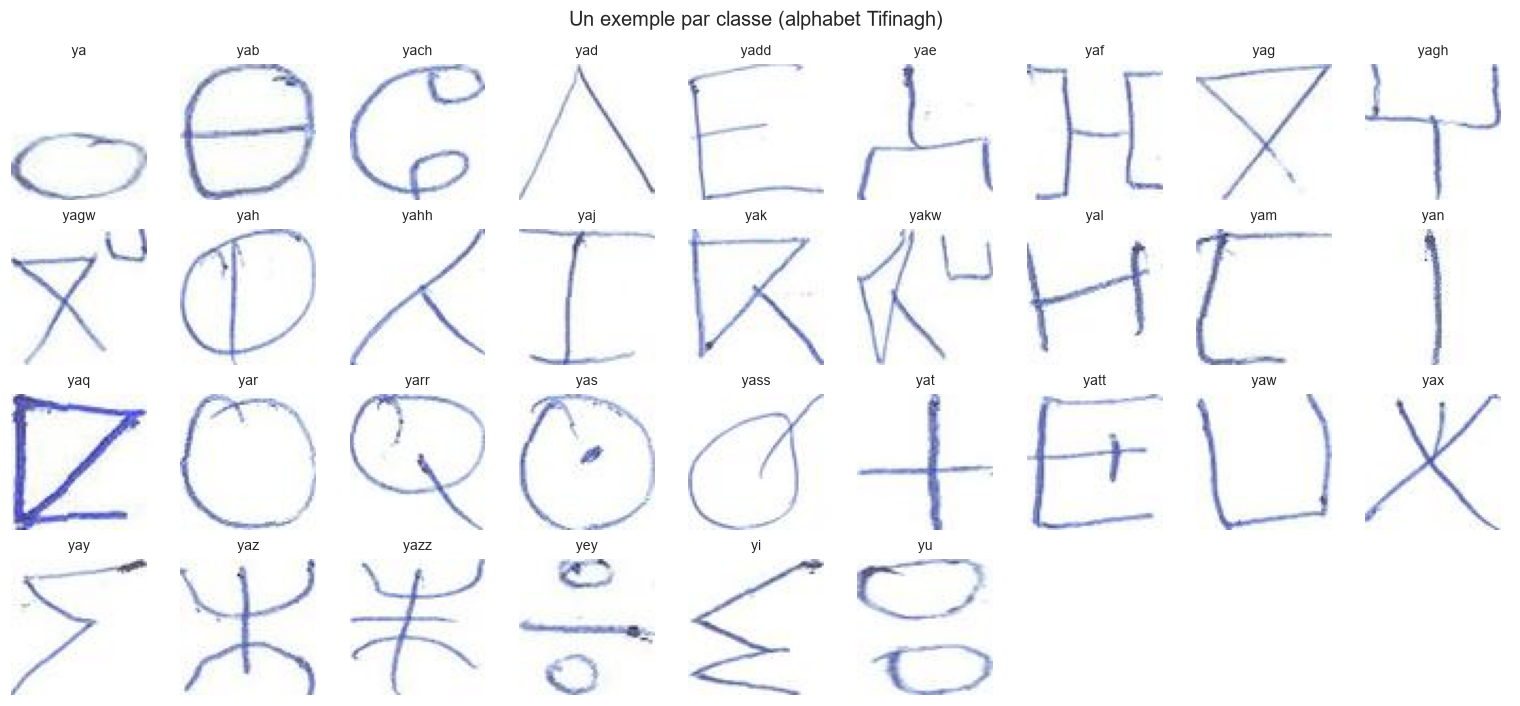

In [19]:
fig, axes = plt.subplots(4, 9, figsize=(14, 6.5))
for ax, d in zip(axes.ravel(), class_dirs):
    f = sorted(d.glob("*.jpeg"))[0]
    ax.imshow(Image.open(f))
    ax.set_title(d.name, fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(class_dirs):]:
    ax.axis("off")
fig.suptitle("Un exemple par classe (alphabet Tifinagh)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_exemples_classes.png", bbox_inches="tight")
plt.show()

## 3. Prétraitement : niveaux de gris 32 × 32 et découpage train / val / test

**Étapes :**

1. Conversion RGB → **niveaux de gris** puis redimensionnement **64 → 32 × 32** ;
2. Mise en cache des tenseurs (une seule lecture des JPEG) ;
3. Normalisation des pixels $x \in [0,1] \rightarrow [-1,1]$ : $\tilde{x} = \dfrac{x - 0.5}{0.5}$ ;
4. Découpage **stratifié** : 70 % entraînement / 15 % validation / 15 % test. 

In [20]:
if CACHE.exists():
    cache = torch.load(CACHE, weights_only=True)
    images, labels, class_names = cache["images"], cache["labels"], cache["class_names"]
else:
    t0 = time.time()
    imgs, lbls = [], []
    for i, d in enumerate(class_dirs):
        for f in sorted(d.glob("*.jpeg")):
            im = Image.open(f).convert("L").resize((32, 32), Image.BILINEAR)
            imgs.append(np.array(im, dtype=np.uint8))
            lbls.append(i)
    images = torch.from_numpy(np.stack(imgs)).unsqueeze(1)   # (N, 1, 32, 32)
    labels = torch.tensor(lbls, dtype=torch.long)
    class_names = CLASS_NAMES
    CACHE.parent.mkdir(exist_ok=True)
    torch.save({"images": images, "labels": labels, "class_names": class_names}, CACHE)
    print(f"Cache construit en {time.time()-t0:.1f} s")

print(f"Images : {tuple(images.shape)} dtype={images.dtype}")
print(f"Labels : {tuple(labels.shape)} classes={len(class_names)}")

Images : (25740, 1, 32, 32) dtype=torch.uint8
Labels : (25740,) classes=33


In [21]:
# Normalisation : [0,1] -> [-1,1]
X = (images.float() / 255.0 - 0.5) / 0.5
y = labels

idx = np.arange(len(y))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y.numpy(), random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50,
                                     stratify=y.numpy()[tmp_idx], random_state=SEED)

train_ds = TensorDataset(X[train_idx], y[train_idx])
val_ds   = TensorDataset(X[val_idx],   y[val_idx])
test_ds  = TensorDataset(X[test_idx],  y[test_idx])

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train : {len(train_ds):5d}  ({100*len(train_ds)/len(X):.1f} %)")
print(f"Val   : {len(val_ds):5d}  ({100*len(val_ds)/len(X):.1f} %)")
print(f"Test  : {len(test_ds):5d}  ({100*len(test_ds)/len(X):.1f} %)")

xb, yb = next(iter(train_loader))
print(f"Batch : images {tuple(xb.shape)} | labels {tuple(yb.shape)} | range [{xb.min():.2f}, {xb.max():.2f}]")

Train : 18018  (70.0 %)
Val   :  3861  (15.0 %)
Test  :  3861  (15.0 %)
Batch : images (128, 1, 32, 32) | labels (128,) | range [-0.52, 1.00]


## 4. Couches paramétrables

Chaque couche est implémentée comme une **classe paramétrable** : tous les hyperparamètres (nombre de filtres, taille du noyau, pas, padding, nombre de neurones, fonction d'activation) sont passés au constructeur, et les poids sont des `nn.Parameter` appris par rétropropagation.

### 4.1 Convolution

$$
(S^{(l)})_{i,j}^{k} = b^{k} + \sum_{u=0}^{K-1}\sum_{v=0}^{K-1}\sum_{c=0}^{C_{in}-1} W^{k}_{u,v,c}\, S^{(l-1)}_{i+u,\, j+v,\, c}
$$

avec $K$ la taille du noyau, $k$ le filtre, $C_{in}$ le nombre de canaux d'entrée. Sans padding ni stride, la sortie est de taille $O = \dfrac{I - K}{s} + 1$ (d'où $32 \to 28$ pour $K=5$).

### 4.2 Sous-échantillonnage (pooling moyen)

$$
(S^{(l)})_{i,j}^{k} = \frac{1}{K^2} \sum_{u=0}^{K-1}\sum_{v=0}^{K-1} S^{(l-1)}_{iK+u,\, jK+v,\, k}
$$

### 4.3 Couche entièrement connectée (fully connected)

$$
y = \sigma(W x + b), \qquad \sigma \in \{\text{ReLU}, \tanh, \text{sigmoid}\}
$$

In [22]:
class ConvLayer(nn.Module):
    """Couche de convolution parametrable (2D)."""

    def __init__(self, in_channels, out_channels, kernel_size=5, stride=1, padding=0, bias=True):
        super().__init__()
        self.in_channels, self.out_channels = in_channels, out_channels
        self.kernel_size, self.stride, self.padding = kernel_size, stride, padding
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))
        self.bias = nn.Parameter(torch.zeros(out_channels)) if bias else None
        bound = 1.0 / math.sqrt(in_channels * kernel_size * kernel_size)   # init de LeCun
        nn.init.uniform_(self.weight, -bound, bound)

    def forward(self, x):
        return F.conv2d(x, self.weight, self.bias, stride=self.stride, padding=self.padding)

    def extra_repr(self):
        return (f"in={self.in_channels}, out={self.out_channels}, "
                f"k={self.kernel_size}, s={self.stride}, p={self.padding}")


class AvgPoolLayer(nn.Module):
    """Couche de pooling moyen parametrable."""

    def __init__(self, kernel_size=2, stride=2):
        super().__init__()
        self.kernel_size, self.stride = kernel_size, stride

    def forward(self, x):
        return F.avg_pool2d(x, kernel_size=self.kernel_size, stride=self.stride)

    def extra_repr(self):
        return f"k={self.kernel_size}, s={self.stride}"


class LinearLayer(nn.Module):
    """Couche fully connected parametrable."""

    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.in_features, self.out_features = in_features, out_features
        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
        bound = 1.0 / math.sqrt(in_features)                              # init de LeCun
        nn.init.uniform_(self.weight, -bound, bound)

    def forward(self, x):
        return F.linear(x, self.weight, self.bias)

    def extra_repr(self):
        return f"in={self.in_features}, out={self.out_features}"


class ActivationLayer(nn.Module):
    """Couche d'activation parametrable : relu | tanh | sigmoid | leaky_relu."""

    _ACTS = {
        "relu": F.relu,
        "tanh": torch.tanh,
        "sigmoid": torch.sigmoid,
        "leaky_relu": lambda t: F.leaky_relu(t, 0.1),
    }

    def __init__(self, activation="relu"):
        super().__init__()
        if activation not in self._ACTS:
            raise ValueError(f"Activation inconnue : {activation} (dispo : {list(self._ACTS)})")
        self.activation = activation

    def forward(self, x):
        return self._ACTS[self.activation](x)

    def extra_repr(self):
        return self.activation


class Flatten(nn.Module):
    """Aplatit (N, C, H, W) -> (N, C*H*W)."""

    def forward(self, x):
        return torch.flatten(x, 1)

## 5. Architecture LeNet-5 (modifiée pour 33 classes)

| Couche | Type | Paramètres | Taille de sortie |
|---|---|---|---|
| Entrée | image | niveaux de gris | 32 × 32 × 1 |
| **C1** | convolution | 6 filtres 5×5 | 28 × 28 × 6 |
| **S2** | avg-pooling | 2×2, stride 2 | 14 × 14 × 6 |
| **C3** | convolution | 16 filtres 5×5 | 10 × 10 × 16 |
| **S4** | avg-pooling | 2×2, stride 2 | 5 × 5 × 16 |
| **C5** | fully connected | 120 neurones | 120 |
| **F6** | fully connected | 84 neurones | 84 |
| **Sortie** | fully connected | **33 neurones** | 33 |

Tous les hyperparamètres (canaux, filtres, noyaux, neurones, activation) sont **paramétrables** à la construction du réseau.

In [23]:
def conv_out(size, kernel, stride=1, padding=0):
    """Taille spatiale apres convolution : O = (I - K + 2P)/s + 1"""
    return (size - kernel + 2 * padding) // stride + 1


def pool_out(size, kernel, stride=None):
    """Taille spatiale apres pooling"""
    stride = kernel if stride is None else stride
    return (size - kernel) // stride + 1


class LeNet5(nn.Module):
    """LeNet-5 parametrable (LeCun et al., 1998) adapte a N classes.

    C1 -> S2 -> C3 -> S4 -> C5 -> F6 -> Sortie
    """

    def __init__(self, in_channels=1, num_classes=33, input_size=32,
                 conv1_out=6, conv2_out=16, kernel_size=5, pool_size=2,
                 fc1=120, fc2=84, activation="relu", dropout=0.0):
        super().__init__()
        self.num_classes = num_classes
        self.activation_name = activation

        # --- C1 : convolution 6 filtres 5x5 ---
        self.c1 = ConvLayer(in_channels, conv1_out, kernel_size)
        self.a1 = ActivationLayer(activation)
        s1 = conv_out(input_size, kernel_size)

        # --- S2 : pooling moyen 2x2 ---
        self.s2 = AvgPoolLayer(pool_size)
        s2 = pool_out(s1, pool_size)

        # --- C3 : convolution 16 filtres 5x5 ---
        self.c3 = ConvLayer(conv1_out, conv2_out, kernel_size)
        self.a3 = ActivationLayer(activation)
        s3 = conv_out(s2, kernel_size)

        # --- S4 : pooling moyen 2x2 ---
        self.s4 = AvgPoolLayer(pool_size)
        s4 = pool_out(s3, pool_size)

        self.flatten_dim = conv2_out * s4 * s4          # 16 * 5 * 5 = 400

        # --- C5 : fully connected 120 neurones ---
        self.c5 = LinearLayer(self.flatten_dim, fc1)
        self.a5 = ActivationLayer(activation)
        # --- F6 : fully connected 84 neurones ---
        self.f6 = LinearLayer(fc1, fc2)
        self.a6 = ActivationLayer(activation)
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        # --- Sortie : num_classes neurones ---
        self.out = LinearLayer(fc2, num_classes)

        self.layers = nn.Sequential(
            self.c1, self.a1, self.s2,
            self.c3, self.a3, self.s4,
            nn.Flatten(1),
            self.c5, self.a5,
            self.f6, self.a6, self.drop,
            self.out,
        )

    def forward(self, x):
        return self.layers(x)

    @torch.no_grad()
    def features(self, x):
        """Renvoie les sorties intermediaires (cartes caracteristiques)."""
        f = {}
        f["C1"] = self.a1(self.c1(x))
        f["S2"] = self.s2(f["C1"])
        f["C3"] = self.a3(self.c3(f["S2"]))
        f["S4"] = self.s4(f["C3"])
        flat = torch.flatten(f["S4"], 1)
        f["C5"] = self.a5(self.c5(flat))
        f["F6"] = self.a6(self.f6(f["C5"]))
        f["OUT"] = self.out(f["F6"])
        return f


def model_summary(model, input_shape=(1, 1, 32, 32), device=DEVICE):
    """Trace les formes des sorties de chaque couche + nombre de parametres."""
    rows, hooks = [], []

    def make_hook(name):
        def h(mod, inp, out):
            shape = tuple(out.shape) if torch.is_tensor(out) else tuple(inp[0].shape)
            n = sum(p.numel() for p in mod.parameters(recurse=False))
            rows.append((name, type(mod).__name__, shape, n))
        return h

    for name, mod in model.named_children():
        hooks.append(mod.register_forward_hook(make_hook(name)))

    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_shape, device=device))
    for h in hooks:
        h.remove()

    print(f"{'Couche':6s} {'Module':16s} {'Sortie':22s} {'Parametres':>10s}")
    print("-" * 58)
    for name, mod, shape, n in rows:
        print(f"{name:6s} {mod:16s} {str(shape):22s} {n:10d}")
    total = sum(p.numel() for p in model.parameters())
    print("-" * 58)
    print(f"{'TOTAL':45s} {total:10d}")

In [24]:
model = LeNet5(
    in_channels=1, num_classes=33, input_size=32,
    conv1_out=6, conv2_out=16, kernel_size=5, pool_size=2,
    fc1=120, fc2=84, activation="relu",
).to(DEVICE)

print(model)
print()
model_summary(model)

LeNet5(
  (c1): ConvLayer(in=1, out=6, k=5, s=1, p=0)
  (a1): ActivationLayer(relu)
  (s2): AvgPoolLayer(k=2, s=2)
  (c3): ConvLayer(in=6, out=16, k=5, s=1, p=0)
  (a3): ActivationLayer(relu)
  (s4): AvgPoolLayer(k=2, s=2)
  (c5): LinearLayer(in=400, out=120)
  (a5): ActivationLayer(relu)
  (f6): LinearLayer(in=120, out=84)
  (a6): ActivationLayer(relu)
  (drop): Identity()
  (out): LinearLayer(in=84, out=33)
  (layers): Sequential(
    (0): ConvLayer(in=1, out=6, k=5, s=1, p=0)
    (1): ActivationLayer(relu)
    (2): AvgPoolLayer(k=2, s=2)
    (3): ConvLayer(in=6, out=16, k=5, s=1, p=0)
    (4): ActivationLayer(relu)
    (5): AvgPoolLayer(k=2, s=2)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): LinearLayer(in=400, out=120)
    (8): ActivationLayer(relu)
    (9): LinearLayer(in=120, out=84)
    (10): ActivationLayer(relu)
    (11): Identity()
    (12): LinearLayer(in=84, out=33)
  )
)

Couche Module           Sortie                 Parametres
---------------------------------------

## 6. Fonctions d'apprentissage et optimisateurs

### 6.1 Fonction de coût

Classification multi-classes : **cross-entropie** (log-vraisemblance négative)

$$
\mathcal{L}(\theta) = -\frac{1}{N}\sum_{i=1}^{N} \log p_{\theta}(y_i \mid x_i)
= -\frac{1}{N}\sum_{i=1}^{N} \log \frac{e^{z_{y_i}}}{\sum_{c=1}^{33} e^{z_c}}
$$

### 6.2 Optimisation

* **SGD** : $\theta_{t+1} = \theta_t - \eta \, g_t$  (avec moment : $v_{t+1} = \mu v_t + g_t$, $\theta_{t+1} = \theta_t - \eta v_{t+1}$)
* **Adam** : $m_{t+1} = \beta_1 m_t + (1-\beta_1)g_t$, $v_{t+1} = \beta_2 v_t + (1-\beta_2)g_t^2$, avec correction de biais et $\theta_{t+1} = \theta_t - \eta \dfrac{\hat m_{t+1}}{\sqrt{\hat v_{t+1}} + \epsilon}$
* **RMSprop** : $\theta_{t+1} = \theta_t - \eta \dfrac{g_t}{\sqrt{E[g^2]_t + \epsilon}}$

In [25]:
def get_optimizer(model, name="adam", lr=1e-3, momentum=0.9, weight_decay=0.0, alpha=0.99):
    """Fabrique d'optimiseur : sgd | adam | adamw | rmsprop."""
    name = name.lower()
    params = model.parameters()
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=momentum, weight_decay=weight_decay)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, alpha=alpha, momentum=momentum, weight_decay=weight_decay)
    raise ValueError(f"Optimiseur inconnu : {name}")


def train_epoch(model, loader, optimizer, criterion, device=DEVICE):
    """Une epoque d'entrainement -> (perte moyenne, accuracy)."""
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device=DEVICE):
    """Evaluation -> (perte, accuracy, y_true, y_pred)."""
    model.eval()
    running_loss, y_true, y_pred = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running_loss += criterion(logits, yb).item() * xb.size(0)
        y_true.append(yb.cpu())
        y_pred.append(logits.argmax(1).cpu())
    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()
    n = len(y_true)
    return running_loss / n, (y_true == y_pred).mean(), y_true, y_pred


def fit(model, train_loader, val_loader, optimizer, criterion,
        epochs=10, scheduler=None, device=DEVICE, verbose=True):
    """Boucle d'entrainement avec suivi train/validation et early stopping sur la val.

    Renvoie l'historique (loss / accuracy par epoque) et les poids de la meilleure epoque.
    """
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "time": []}
    best_wts, best_val, best_epoch = copy.deepcopy(model.state_dict()), -1.0, 0

    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)
        if scheduler is not None:
            scheduler.step()
        dt = time.time() - t0

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["time"].append(dt)

        if va_acc > best_val:
            best_val, best_epoch = va_acc, ep
            best_wts = copy.deepcopy(model.state_dict())

        if verbose:
            lr = optimizer.param_groups[0]["lr"]
            print(f"Epoch {ep:02d}/{epochs} | {dt:5.1f}s | lr={lr:.2e} | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4%} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4%}")

    model.load_state_dict(best_wts)
    if verbose:
        print(f">>> Meilleur modele : epoch {best_epoch} (val acc {best_val:.4%})")
    history["best_val_acc"] = best_val
    history["best_epoch"] = best_epoch
    return history

### Visualisation des courbes de loss / accuracy

In [26]:
def plot_history(history, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    ep = np.arange(1, len(history["train_loss"]) + 1)

    axes[0].plot(ep, history["train_loss"], "o-", label="Entraînement")
    axes[0].plot(ep, history["val_loss"], "s-", label="Validation")
    axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Loss (cross-entropie)")
    axes[0].set_title("Évolution de la loss"); axes[0].legend()

    axes[1].plot(ep, np.array(history["train_acc"]) * 100, "o-", label="Entraînement")
    axes[1].plot(ep, np.array(history["val_acc"]) * 100, "s-", label="Validation")
    axes[1].axhline(history["best_val_acc"] * 100, ls="--", c="gray", lw=1)
    axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Accuracy (%)")
    axes[1].set_title("Évolution de l'accuracy"); axes[1].legend()

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()

## 7. Expérience 1 — **Adam**

Hyperparamètres : $\eta = 10^{-3}$, $\beta_1 = 0.9$, $\beta_2 = 0.999$, batch = 128, 10 époques.

In [27]:
EPOCHS = 10
CRITERION = nn.CrossEntropyLoss()

model_adam = LeNet5(in_channels=1, num_classes=33, activation="relu").to(DEVICE)
opt_adam = get_optimizer(model_adam, name="adam", lr=1e-3)

t0 = time.time()
hist_adam = fit(model_adam, train_loader, val_loader, opt_adam, CRITERION, epochs=EPOCHS)
print(f"Durée totale : {time.time()-t0:.1f} s")

Epoch 01/10 |   4.1s | lr=1.00e-03 | train loss 2.4560 acc 32.4065% | val loss 1.3460 acc 60.9428%
Epoch 02/10 |   2.4s | lr=1.00e-03 | train loss 0.9833 acc 73.3045% | val loss 0.8394 acc 76.7159%
Epoch 03/10 |   3.9s | lr=1.00e-03 | train loss 0.6421 acc 83.0503% | val loss 0.5919 acc 84.2528%
Epoch 04/10 |   5.4s | lr=1.00e-03 | train loss 0.4698 acc 87.4958% | val loss 0.4327 acc 88.5781%
Epoch 05/10 |   6.1s | lr=1.00e-03 | train loss 0.3653 acc 90.2764% | val loss 0.3641 acc 89.8731%
Epoch 06/10 |   6.3s | lr=1.00e-03 | train loss 0.3051 acc 91.6528% | val loss 0.2993 acc 91.9710%
Epoch 07/10 |   6.2s | lr=1.00e-03 | train loss 0.2632 acc 92.9570% | val loss 0.2777 acc 91.9710%
Epoch 08/10 |   6.3s | lr=1.00e-03 | train loss 0.2253 acc 93.7451% | val loss 0.2527 acc 92.7739%
Epoch 09/10 |   6.3s | lr=1.00e-03 | train loss 0.1996 acc 94.4278% | val loss 0.2142 acc 93.9653%
Epoch 10/10 |   6.3s | lr=1.00e-03 | train loss 0.1775 acc 94.8329% | val loss 0.1899 acc 94.6905%
>>> Meille

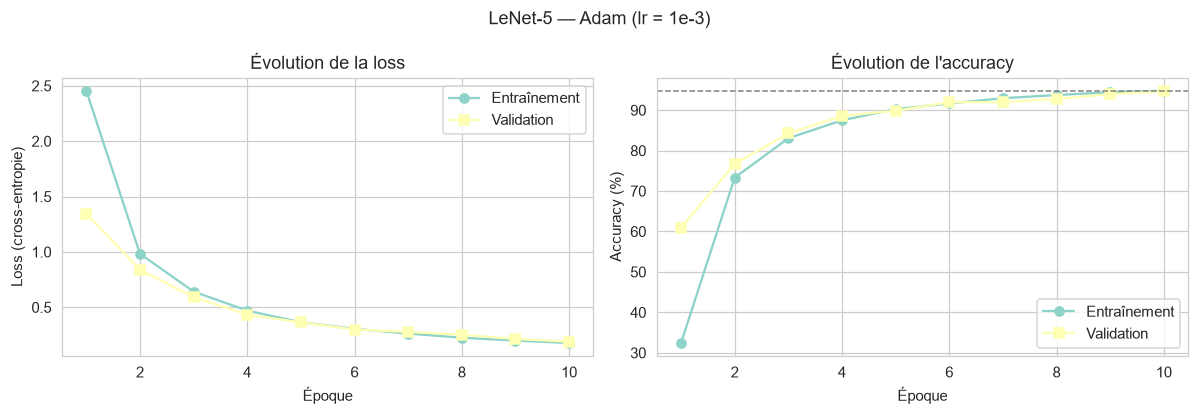

In [28]:
plot_history(hist_adam, "LeNet-5 — Adam (lr = 1e-3)", "02_courbes_adam.png")

## 8. Expérience 2 — **SGD** avec momentum

Hyperparamètres : $\eta = 0{,}01$, momentum $\mu = 0{,}9$, même découpage et même nombre d'époques (comparaison équitable).

In [29]:
model_sgd = LeNet5(in_channels=1, num_classes=33, activation="relu").to(DEVICE)
opt_sgd = get_optimizer(model_sgd, name="sgd", lr=0.01, momentum=0.9)

t0 = time.time()
hist_sgd = fit(model_sgd, train_loader, val_loader, opt_sgd, CRITERION, epochs=EPOCHS)
print(f"Durée totale : {time.time()-t0:.1f} s")

Epoch 01/10 |   6.6s | lr=1.00e-02 | train loss 3.4945 acc 3.9905% | val loss 3.4903 acc 3.9886%
Epoch 02/10 |   6.6s | lr=1.00e-02 | train loss 3.4236 acc 8.6081% | val loss 2.9934 acc 13.4162%
Epoch 03/10 |   5.3s | lr=1.00e-02 | train loss 1.4924 acc 57.4703% | val loss 0.8128 acc 74.8252%
Epoch 04/10 |   2.9s | lr=1.00e-02 | train loss 0.5821 acc 83.9494% | val loss 0.5198 acc 85.4442%
Epoch 05/10 |   2.7s | lr=1.00e-02 | train loss 0.4129 acc 88.4726% | val loss 0.3475 acc 89.1220%
Epoch 06/10 |   3.8s | lr=1.00e-02 | train loss 0.3034 acc 91.2199% | val loss 0.3288 acc 90.1839%
Epoch 07/10 |   3.7s | lr=1.00e-02 | train loss 0.2323 acc 93.1957% | val loss 0.2606 acc 92.2300%
Epoch 08/10 |   3.8s | lr=1.00e-02 | train loss 0.2031 acc 93.9560% | val loss 0.2549 acc 92.1782%
Epoch 09/10 |   3.9s | lr=1.00e-02 | train loss 0.1813 acc 94.3945% | val loss 0.2106 acc 93.4991%
Epoch 10/10 |   3.9s | lr=1.00e-02 | train loss 0.1576 acc 95.3269% | val loss 0.1979 acc 94.6387%
>>> Meilleur 

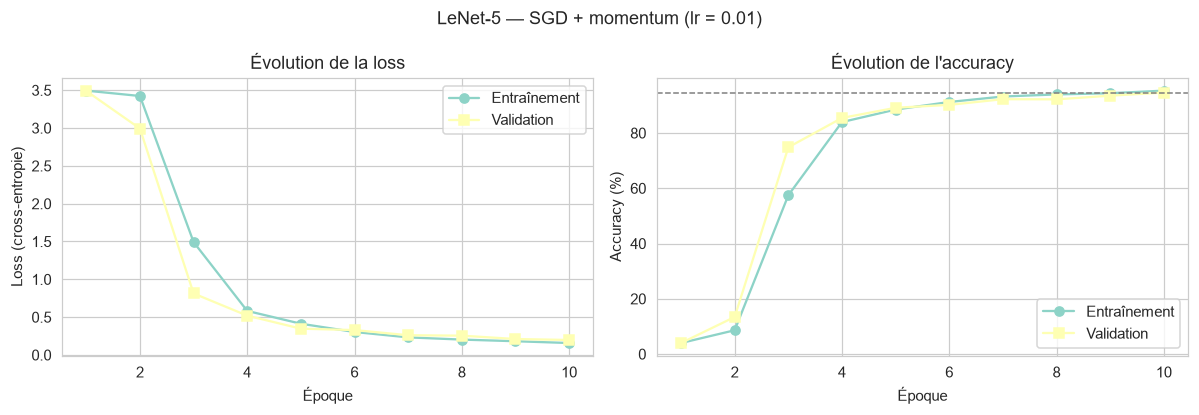

In [30]:
plot_history(hist_sgd, "LeNet-5 — SGD + momentum (lr = 0.01)", "03_courbes_sgd.png")

## 9. Expérience 3 — **RMSprop** (bonus)

In [ ]:
model_rms = LeNet5(in_channels=1, num_classes=33, activation="relu").to(DEVICE)
opt_rms = get_optimizer(model_rms, name="rmsprop", lr=1e-3, momentum=0.9)

t0 = time.time()
hist_rms = fit(model_rms, train_loader, val_loader, opt_rms, CRITERION, epochs=EPOCHS)
print(f"Durée totale : {time.time()-t0:.1f} s")

Epoch 01/10 |   3.7s | lr=1.00e-03 | train loss 2.2318 acc 37.0407% | val loss 0.8842 acc 73.3748%
Epoch 02/10 |   1.9s | lr=1.00e-03 | train loss 0.6015 acc 82.2511% | val loss 0.5651 acc 82.5952%
Epoch 03/10 |   1.6s | lr=1.00e-03 | train loss 0.3655 acc 89.1220% | val loss 0.3386 acc 90.4688%
Epoch 04/10 |   1.5s | lr=1.00e-03 | train loss 0.2984 acc 90.8480% | val loss 0.2517 acc 92.5149%
Epoch 05/10 |   1.7s | lr=1.00e-03 | train loss 0.2609 acc 91.9525% | val loss 0.2958 acc 91.5048%


In [ ]:
plot_history(hist_rms, "LeNet-5 — RMSprop (lr = 1e-3)", "04_courbes_rmsprop.png")

# --- Comparaison des trois optimisateurs ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ep = np.arange(1, EPOCHS + 1)
for hist, name, c in [(hist_sgd, "SGD", "tab:blue"),
                      (hist_adam, "Adam", "tab:orange"),
                      (hist_rms, "RMSprop", "tab:green")]:
    axes[0].plot(ep, hist["val_loss"], "o-", color=c, label=name)
    axes[1].plot(ep, np.array(hist["val_acc"]) * 100, "o-", color=c, label=name)
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Loss (validation)"); axes[0].legend()
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Accuracy validation (%)"); axes[1].legend()
axes[0].set_title("Loss de validation"); axes[1].set_title("Accuracy de validation")
fig.suptitle("Comparaison des optimisateurs")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_comparaison_optimisateurs.png", bbox_inches="tight")
plt.show()

## 10. Évaluation sur le jeu de test

On retient le meilleur modèle de validation puis on l'évalue sur le **jeu de test** (15 %, jamais vu pendant l'entraînement) : accuracy globale, precision / recall / F1 **par classe** et matrice de confusion.

In [ ]:
histories = {"SGD": hist_sgd, "Adam": hist_adam, "RMSprop": hist_rms}
best_name = max(histories, key=lambda k: histories[k]["best_val_acc"])
print("Meilleur optimiseur (val) :", best_name,
      f"= {histories[best_name]['best_val_acc']:.4%}")

best_model = {"SGD": model_sgd, "Adam": model_adam, "RMSprop": model_rms}[best_name]
test_loss, test_acc, y_true, y_pred = evaluate(best_model, test_loader, CRITERION)
print(f"\n>>> TEST — loss {test_loss:.4f} | accuracy {test_acc:.4%} "
      f"({(y_true == y_pred).sum()} / {len(y_true)})")

In [ ]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

In [ ]:
# --- Matrice de confusion ---
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / cm.sum(1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.heatmap(cm, cmap="Blues", cbar=False, ax=axes[0], xticklabels=class_names,
            yticklabels=class_names)
axes[0].set_title("Matrice de confusion (comptes)"); axes[0].set_xlabel("Prédit"); axes[0].set_ylabel("Vrai")

sns.heatmap(cm_norm, cmap="viridis", ax=axes[1], xticklabels=class_names,
            yticklabels=class_names, vmin=0, vmax=1)
axes[1].set_title("Matrice de confusion (normalisée par classe)"); axes[1].set_xlabel("Prédit"); axes[1].set_ylabel("Vrai")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_matrice_confusion.png", bbox_inches="tight")
plt.show()

# --- Paires de classes les plus confondues (bonus) ---
pairs = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            pairs.append((cm[i, j], class_names[i], class_names[j]))
pairs.sort(reverse=True)
print("Top 10 des confusions (vrai -> prédit) :")
for n, i, j in pairs[:10]:
    print(f"  {i:5s} -> {j:5s} : {n}")

## 11. Cartes caractéristiques (*feature maps*)

On visualise les sorties des couches **C1** (6 cartes 28×28), **S2** (6 cartes 14×14), **C3** (16 cartes 10×10) et **S4** (16 cartes 5×5) pour une image du jeu de test.

In [ ]:
def show_feature_maps(model, x, class_names, fname, n_c3=16):
    model.eval()
    with torch.no_grad():
        f = model.features(x.unsqueeze(0).to(DEVICE))

    def norm(t):
        t = t[0].cpu().numpy()
        lo, hi = t.min(), t.max()
        return (t - lo) / (hi - lo + 1e-8)

    groups = [("Entrée", [norm(x.unsqueeze(0))], 1),
              ("C1 — 6 filtres 5×5", [norm(f["C1"])], 6),
              ("S2 — pooling 2×2", [norm(f["S2"])], 6),
              ("C3 — 16 filtres 5×5", [norm(f["C3"])], n_c3),
              ("S4 — pooling 2×2", [norm(f["S4"])], n_c3)]

    n_cols = max(m for _, maps, m in groups)
    n_rows = len(groups)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.35 * n_cols, 1.45 * n_rows))
    for r, (title, maps, n_maps) in enumerate(groups):
        ax_row = axes[r] if n_rows > 1 else axes
        ax_row = np.atleast_1d(ax_row)
        for c in range(n_cols):
            ax = ax_row[c]
            ax.axis("off")
            if c < n_maps:
                ax.imshow(maps[0][c], cmap="viridis")
                if c == 0:
                    ax.set_title(title, fontsize=9, loc="left")
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()

    logits = f["OUT"][0]
    pred = int(logits.argmax())
    print(f"Prediction : {class_names[pred]} ({F.softmax(logits, dim=-1)[pred]:.2%})")


# 3 exemples : 2 corrects + 1 erreur
pred_all = best_model(X[test_idx][:200].to(DEVICE)).argmax(1).cpu().numpy()
y_all = y[test_idx][:200].numpy()
correct_idx = np.where(pred_all == y_all)[0][:2]
wrong_idx = np.where(pred_all != y_all)[0][:1]
for k, (i, tag) in enumerate([(correct_idx[0], "correct"), (correct_idx[1], "correct"),
                              (wrong_idx[0] if len(wrong_idx) else correct_idx[0], "erreur")]):
    print(f"--- Exemple {k+1} ({tag}) ---")
    show_feature_maps(best_model, X[test_idx][i], class_names, f"07_feature_maps_{k+1}.png")

## 12. Résultats qualitatifs : prédictions correctes / erreurs

In [ ]:
n_show = 24
sel = test_idx[:n_show]
x_show, y_show = X[sel], y[sel]
with torch.no_grad():
    p_show = best_model(x_show.to(DEVICE)).argmax(1).cpu().numpy()

fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for ax, img, yt, yp in zip(axes.ravel(), x_show, y_show.numpy(), p_show):
    ax.imshow(img[0], cmap="gray")
    ok = yt == yp
    ax.set_title(f"V:{class_names[yt]}  P:{class_names[yp]}", fontsize=8,
                 color="tab:green" if ok else "tab:red")
    ax.axis("off")
fig.suptitle("Prédictions du modèle (vert = correct, rouge = erreur)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_predictions.png", bbox_inches="tight")
plt.show()

## 13. Bilan et sauvegarde

In [ ]:
# --- Tableau comparatif quantitatif ---
rows = []
for name, hist in histories.items():
    m = {"SGD": model_sgd, "Adam": model_adam, "RMSprop": model_rms}[name]
    vl, va, _, _ = evaluate(m, val_loader, CRITERION)
    tl, ta, _, _ = evaluate(m, test_loader, CRITERION)
    rows.append({"optimiseur": name,
                 "best_val_acc": hist["best_val_acc"],
                 "test_loss": tl, "test_acc": ta,
                 "temps_total_s": sum(hist["time"])})

import pandas as pd
df = pd.DataFrame(rows).set_index("optimiseur")
df["test_acc_%"] = (df["test_acc"] * 100).round(2)
df["best_val_acc_%"] = (df["best_val_acc"] * 100).round(2)
df["temps_total_s"] = df["temps_total_s"].round(1)
print(df[["best_val_acc_%", "test_loss", "test_acc_%", "temps_total_s"]].to_string())

results = {"dataset": "AMHCD", "n_classes": len(class_names),
           "n_images": int(len(X)),
           "split": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)},
           "batch_size": BATCH_SIZE, "epochs": EPOCHS, "seed": SEED,
           "device": str(DEVICE),
           "architecture": {"conv1_out": 6, "conv2_out": 16, "fc1": 120, "fc2": 84,
                            "num_classes": 33, "activation": "relu"},
           "experiments": rows,
           "best": {"optimizer": best_name, "test_acc": float(test_acc),
                    "test_loss": float(test_loss)}}
(ROOT / "results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")

torch.save({
    "model_state_dict": best_model.state_dict(),
    "class_names": class_names,
    "config": results["architecture"],
}, MODEL_DIR / "lenet5_amhcd_best.pt")

print(f"\nModele sauvegarde dans {MODEL_DIR / 'lenet5_amhcd_best.pt'}")
print(f"Resultats sauvegardes dans {ROOT / 'results.json'}")
print(f"Figures dans {FIG_DIR}")

### Conclusion

* LeNet-5, implémenté sous forme de **couches paramétrables**, atteint une accuracy élevée sur le jeu de test du corpus **AMHCD** (33 caractères Tifinagh) ;
* La comparaison **SGD / Adam / RMSprop** montre que les méthodes adaptatives (Adam, RMSprop) convergent plus vite et plus stablement que SGD à pas constant ;
* Les **cartes caractéristiques** montrent la hiérarchie des représentations : bords et orientations en C1, motifs plus complexes en C3 ;
* La **matrice de confusion** met en évidence les classes visuellement proches (ex. `yazz`/`yaz`, `yatt`/`yat`, `yadd`/`yad`).

**Pistes d'amélioration (bonus)** : augmentation de données (translations/rotations), dropout + weight decay, planificateur de learning rate (*warmup / cosine*), recouplage C3 (connexions partielles d'origine), fine-tuning d'un CNN plus profond (ResNet-18).